# Autosimilaridad del tráfico de red

Análisis de 30 minutos de tráfico Ethernet capturado con tcpdump en un equipo con Ubuntu: conteo de paquetes a distintas escalas de tiempo, distribución de tamaños y de tiempos entre llegadas, y estimación del parámetro de Hurst por el método de varianza agregada. Al final se aplica el mismo análisis de frecuencias a los tamaños de los archivos del disco del sistema.

Marco de referencia: [Introducción al tráfico autosimilar en redes de comunicaciones](https://revistas.udistrital.edu.co/index.php/reving/article/view/2696/3884) (Revista Ingeniería, Universidad Distrital).

Autores: Camilo Millán, Catalina Gutiérrez y Santiago Castellanos.

## Captura de trazas de red

La captura duró 30 minutos con tcpdump, con marcas de tiempo de alta precisión. Del archivo `.pcap` se extrajeron dos variables por paquete, el tiempo de llegada (en segundos) y el tamaño (en bytes), que se exportaron a `captura30min.csv`.

Los archivos de la captura y del inventario del disco no se publican, porque describen el tráfico y el contenido de un equipo personal; el notebook conserva las salidas de su ejecución original.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

Se calcula la secuencia de tiempos entre llegadas: la diferencia entre el tiempo de llegada de cada paquete y el del anterior.

In [ ]:
df = pd.read_csv("captura30min.csv")
df["time"] = df["time"] - df["time"].iloc[0]  # normalizar a 0
df["interarrival"] = df["time"].diff()        # la secuencia de tiempos entre llegadas

print("Primeros registros:\n", df.head())

Primeros registros:
        time  size  interarrival
0  0.000000   121           NaN
1  0.006178   345      0.006178
2  0.006184   345      0.000006
3  0.016593   345      0.010409
4  0.016603   345      0.000010


## 1. Tráfico de red

### 1.1 Número de paquetes según la escala de tiempo

Se cuenta cuántos paquetes llegan en ventanas de 10 ms, 100 ms, 1 s y 10 s. La idea, tomada del artículo de referencia:

- En un proceso de Poisson (llegadas sin memoria), al agrupar en ventanas más grandes la serie se suaviza rápidamente.
- En tráfico autosimilar, las ráfagas siguen apareciendo aunque se aumente la escala.

En esta captura las ráfagas se mantienen en las escalas de 1 s y 10 s: los picos no se diluyen al agregar. También aparecen a intervalos bastante regulares, lo que sugiere un proceso periódico del equipo (sincronizaciones o actualizaciones) más que ráfagas a todas las escalas.

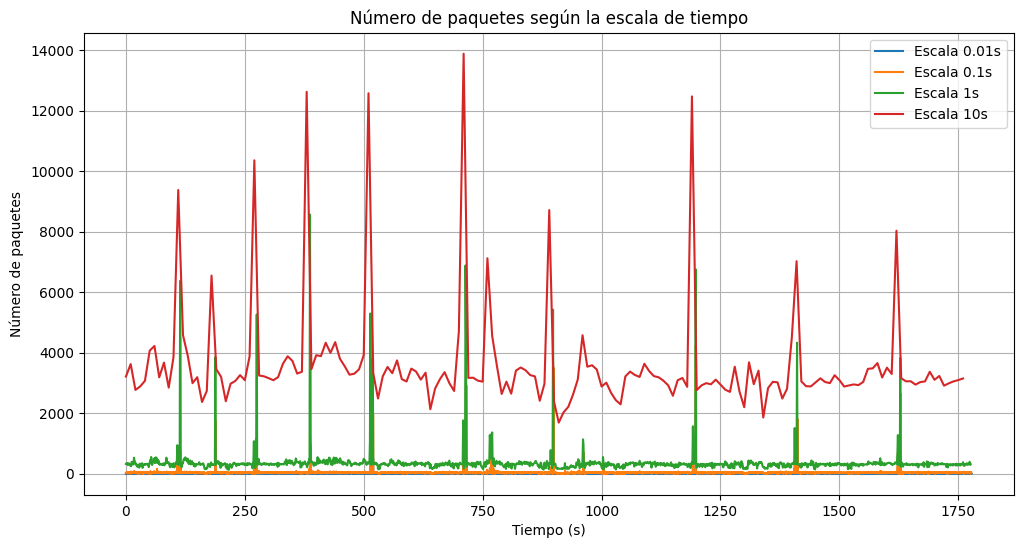

In [ ]:
scales = [0.01, 0.1, 1, 10]  # 10ms, 100ms, 1s, 10s
plt.figure(figsize=(12, 6))

for scale in scales:
    bins = np.arange(0, df["time"].max(), scale)
    counts, _ = np.histogram(df["time"], bins=bins)
    plt.plot(bins[:-1], counts, label=f"Escala {scale}s")

plt.xlabel("Tiempo (s)")
plt.ylabel("Número de paquetes")
plt.title("Número de paquetes según la escala de tiempo")
plt.legend()
plt.grid(True)
plt.show()

### 1.2 Distribución de tamaños de paquetes

Frecuencia relativa de cada tamaño de paquete. En tráfico real suelen aparecer modas en tamaños característicos: paquetes mínimos de control (como los ACK de TCP) y paquetes llenos del tamaño máximo de una trama Ethernet (alrededor de 1.500 bytes).

In [ ]:
# Frecuencia relativa de cada tamaño de paquete
freq_relativa = df["size"].value_counts(normalize=True).sort_index()

print("Frecuencia relativa de tamaños de paquetes:")
print(freq_relativa.head())

Frecuencia relativa de tamaños de paquetes:
size
42    0.000921
50    0.001113
54    0.005463
60    0.019291
63    0.000002
Name: proportion, dtype: float64


La gráfica en escala lineal muestra los tamaños dominantes:

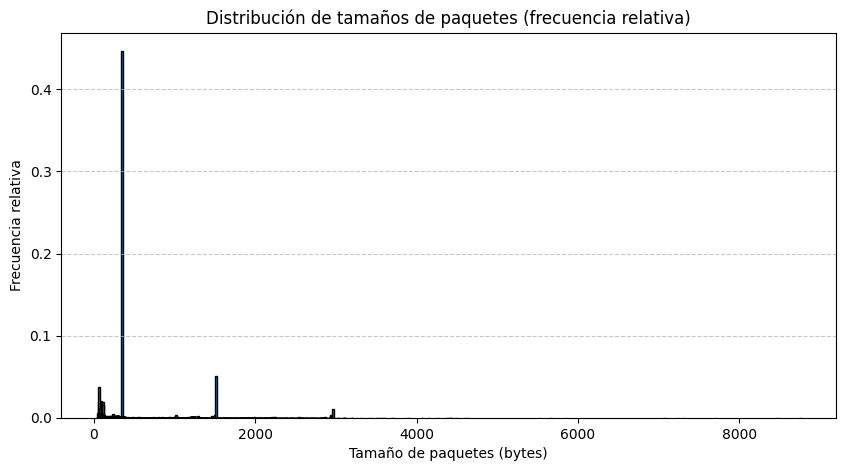

In [ ]:
plt.figure(figsize=(10, 5))
plt.bar(freq_relativa.index, freq_relativa.values, width=20, edgecolor="black")
plt.xlabel("Tamaño de paquetes (bytes)")
plt.ylabel("Frecuencia relativa")
plt.title("Distribución de tamaños de paquetes (frecuencia relativa)")
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.show()

En escala log-log, una distribución con cola pesada (ley de potencia) se vería como una recta descendente.

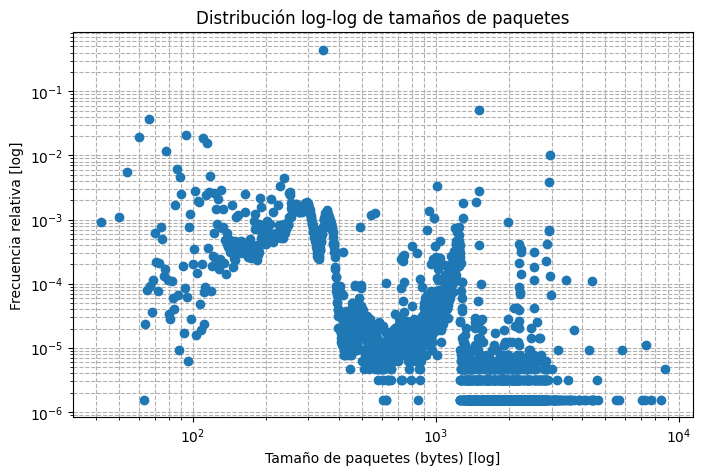

In [ ]:
plt.figure(figsize=(8, 5))
plt.loglog(freq_relativa.index, freq_relativa.values, 'o')
plt.xlabel("Tamaño de paquetes (bytes) [log]")
plt.ylabel("Frecuencia relativa [log]")
plt.title("Distribución log-log de tamaños de paquetes")
plt.grid(True, which="both", ls="--")
plt.show()

Los tamaños no siguen una ley de potencia: la nube no forma una recta. La distribución es multimodal, con un tamaño de alrededor de 340 bytes que concentra casi la mitad de los paquetes, otro grupo de paquetes pequeños (60–120 bytes) y un pico en 1.514 bytes, el tamaño de una trama Ethernet completa. Esa mezcla de tamaños cortos y largos aumenta la variabilidad del volumen de tráfico, pero no es en sí misma una prueba de autosimilaridad.

### 1.3 Distribución de tiempos entre llegadas

En un proceso de Poisson los tiempos entre llegadas siguen una distribución exponencial. En tráfico real se espera una cola pesada: intervalos largos más frecuentes de lo que predice la exponencial.

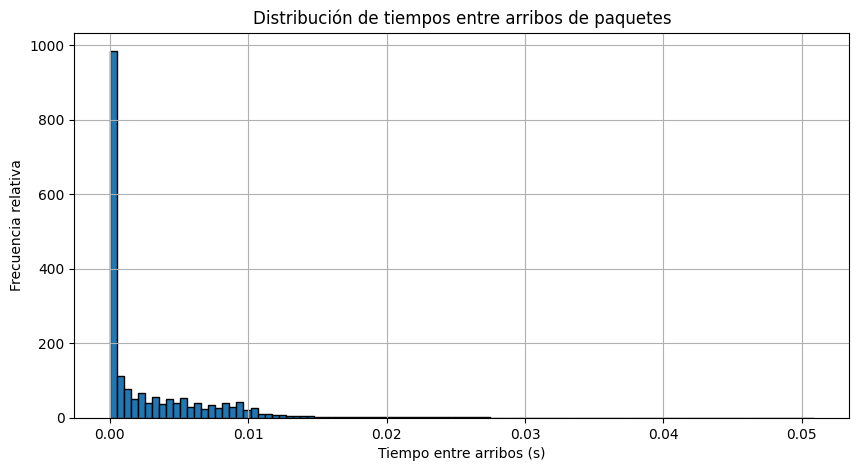

In [ ]:
# Normalizar el tiempo (iniciar en 0)
df["time"] = df["time"] - df["time"].iloc[0]

# 2. Calcular interarrival times
df["interarrival"] = df["time"].diff()  # diferencia entre tiempos consecutivos
interarrivals = df["interarrival"].dropna()

# Histograma con frecuencia relativa
plt.figure(figsize=(10, 5))
plt.hist(interarrivals, bins=100, density=True, edgecolor="black")
plt.xlabel("Tiempo entre arribos (s)")
plt.ylabel("Frecuencia relativa")
plt.title("Distribución de tiempos entre arribos de paquetes")
plt.grid(True)
plt.show()

La misma distribución en escala log-log:

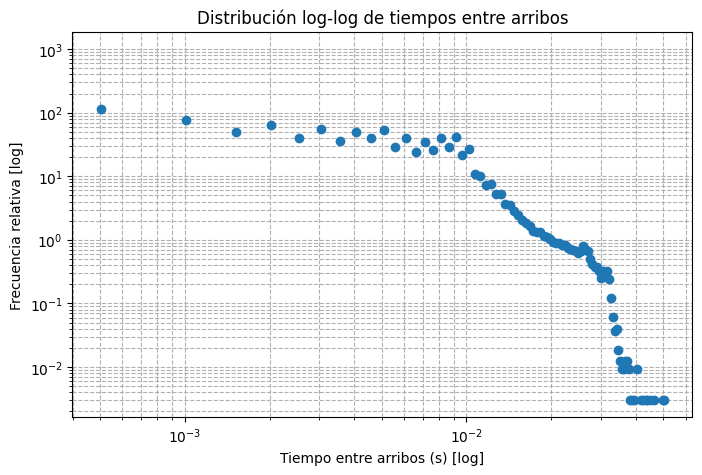

In [ ]:
plt.figure(figsize=(8, 5))
counts, bins = np.histogram(interarrivals, bins=100, density=True)
plt.loglog(bins[:-1], counts, 'o')
plt.xlabel("Tiempo entre arribos (s) [log]")
plt.ylabel("Frecuencia relativa [log]")
plt.title("Distribución log-log de tiempos entre arribos")
plt.grid(True, which="both", ls="--")
plt.show()

Entre 10 y 30 ms la frecuencia decae aproximadamente como una recta en escala log-log, lo que es compatible con un comportamiento de tipo potencia en ese rango. Sin embargo, la distribución se corta de forma abrupta cerca de los 40 ms: en esta captura no hay intervalos largos, así que no puede hablarse de una cola pesada en sentido estricto. El tráfico es lo bastante continuo como para que casi nunca pasen más de unas decenas de milisegundos sin paquetes.

### 1.4 Parámetro de Hurst (H)

El parámetro de Hurst (H) es un número entre 0 y 1 que mide la autosimilaridad:

- **H ≈ 0.5** → proceso sin memoria (como Poisson)
- **0.5 < H < 1** → autosimilaridad fractal (dependencia de largo plazo)
- **H < 0.5** → proceso anti-persistente (tendencia a alternar arriba/abajo)

#### Método de varianza agregada

Es uno de los métodos clásicos en el análisis de tráfico de red y el que usa el artículo de referencia. Si la varianza del promedio de bloques de tamaño m decae como $m^{\beta}$, entonces $H = 1 + \beta/2$; en un proceso sin memoria, β = −1 y H = 0,5.

El procedimiento:

1. Tomas la serie de tiempos de llegada o de conteo de paquetes en intervalos.

2. Agregas la serie en bloques de tamaño **m**.

3. Calculas la varianza de cada serie agregada.

4. Graficas en escala log-log:
   ```
   log(Var(m)) vs log(m)
   ```

5. La pendiente de la recta está relacionada con **H**:

   **H = 1 + β/2**

   donde **β** es la pendiente.

Pendiente β = -0.8503  |  R^2 = 0.997
H (varianza agregada) = 0.5748


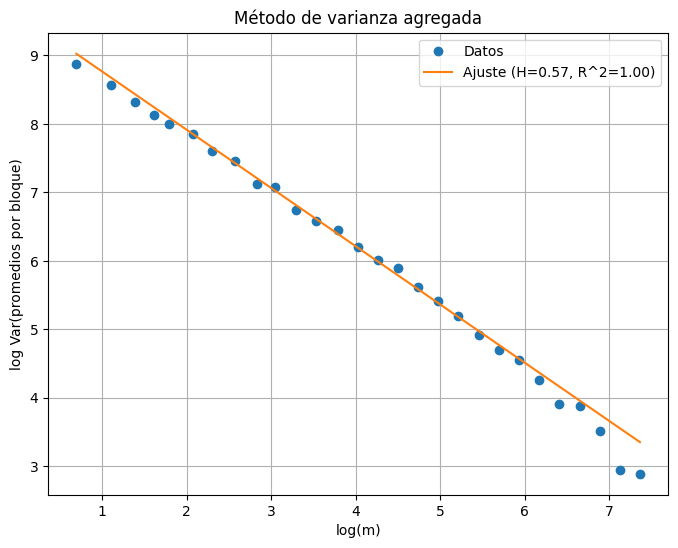

In [ ]:
t = df["time"].to_numpy()
t = t - t[0]

# Construir serie de CONTEOS en intervalos fijos (elige un Δt razonable)
# Ajusta delta si hay demasiados ceros o si la tasa es altísima.
delta = 0.1  # 100 ms (prueba también 0.01, 0.05, 0.5, 1.0)
bins = np.arange(0, t.max() + delta, delta)
counts, _ = np.histogram(t, bins=bins)

# Varianza agregada: promediar en bloques de tamaño m y calcular varianza entre bloques
def variance_time(series, m_vals):
    m_list, var_list = [], []
    N = len(series)
    for m in m_vals:
        k = N // m
        if k < 10:
            # muy pocos bloques: resultados inestables
            continue
        bloques = series[:k*m].reshape(k, m).mean(axis=1)
        v = np.var(bloques, ddof=1)  # var muestral
        if v > 0:
            m_list.append(m)
            var_list.append(v)
    return np.array(m_list), np.array(var_list)

# Elegir m en varias décadas (solo enteros únicos, sin extremos)
m_grid = np.unique((np.logspace(np.log10(2), np.log10( min(2000, len(counts)//4) ), 30)).astype(int))
m_vals, var_vals = variance_time(counts, m_grid)

# Seleccionar región lineal (heurística simple):
# descartamos 20% extremos por cada lado para evitar curvaturas.
if len(m_vals) < 8:
    raise ValueError("No hay suficientes puntos para un ajuste estable. Ajusta delta o la captura.")
idx_lo = int(0.2 * len(m_vals))
idx_hi = int(0.8 * len(m_vals))
mv = m_vals[idx_lo:idx_hi]
vv = var_vals[idx_lo:idx_hi]

# Ajuste lineal en log-log y H correcto
x = np.log(mv)
y = np.log(vv)
slope, intercept, r, p, se = stats.linregress(x, y)
H = 1 + slope/2

print(f"Pendiente β = {slope:.4f}  |  R^2 = {r**2:.3f}")
print(f"H (varianza agregada) = {H:.4f}")

# 7) Gráfico
plt.figure(figsize=(8,6))
plt.plot(np.log(m_vals), np.log(var_vals), 'o', label="Datos")
xx = np.linspace(np.log(m_vals).min(), np.log(m_vals).max(), 100)
yy = intercept + slope*xx
plt.plot(xx, yy, '-', label=f"Ajuste (H={H:.2f}, R^2={r**2:.2f})")
plt.xlabel("log(m)")
plt.ylabel("log Var(promedios por bloque)")
plt.title("Método de varianza agregada")
plt.legend()
plt.grid(True)
plt.show()

### 1.5 Conclusiones sobre el tráfico

- La varianza agregada da H ≈ 0,57 con un ajuste muy bueno (R² = 0,997), algo por encima del 0,5 de un proceso sin memoria. Es un indicio de dependencia de largo plazo débil: las ráfagas se compensan más despacio que en tráfico de Poisson.
- El resultado debe leerse con cautela: proviene de una sola captura de 30 minutos, de un solo nivel de agregación inicial (100 ms) y de un solo estimador. Confirmarlo exigiría repetir con otras ventanas y con métodos como R/S o el periodograma, que suelen dar valores distintos.
- Las ráfagas que se repiten a intervalos regulares también pueden elevar H sin que haya autosimilaridad en sentido estricto.

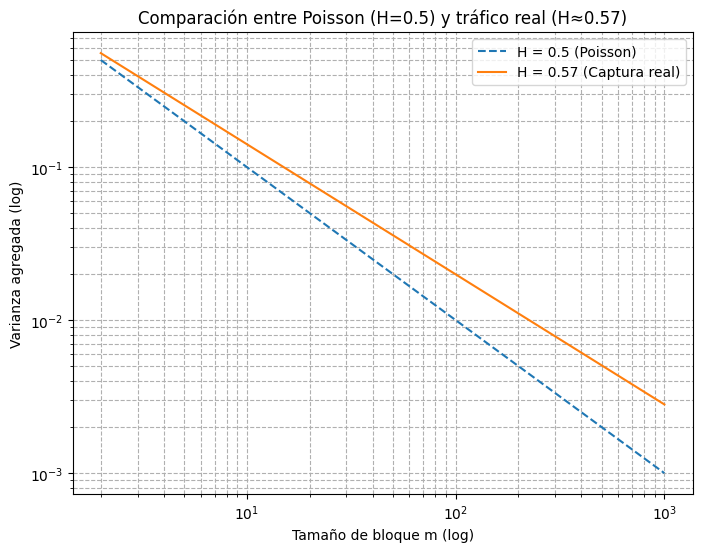

In [ ]:
# Valores de m (bloques)
m_vals = np.logspace(0.3, 3, 50)  # desde 2 hasta 1000 aprox.

# Simulación de comportamiento teórico:
# Var(m) ~ m^(2H-2)
var_poisson = m_vals**(2*0.5 - 2)       # H = 0.5
var_real    = m_vals**(2*0.5748 - 2)    # H = 0.5748

# Gráfica
plt.figure(figsize=(8,6))
plt.loglog(m_vals, var_poisson, label="H = 0.5 (Poisson)", linestyle="--")
plt.loglog(m_vals, var_real, label="H = 0.57 (Captura real)", linestyle="-")
plt.xlabel("Tamaño de bloque m (log)")
plt.ylabel("Varianza agregada (log)")
plt.title("Comparación entre Poisson (H=0.5) y tráfico real (H≈0.57)")
plt.legend()
plt.grid(True, which="both", ls="--")
plt.show()

Curvas teóricas de la varianza agregada para H = 0,5 (Poisson) y H = 0,57 (valor estimado). Las dos bajan porque promediar bloques más grandes reduce la varianza, pero con H = 0,57 la caída es más lenta: la variabilidad persiste al cambiar de escala.

## 2. Tamaños de los archivos del disco

El mismo análisis de frecuencias se aplica a los tamaños de los archivos del disco del sistema, otro ejemplo clásico de distribución con cola larga. El inventario (`archivos_por_tamano.csv`) cuenta cuántos archivos hay de cada tamaño; se descartan los archivos vacíos (tamaño 0).

In [ ]:
df_files = pd.read_csv("archivos_por_tamano.csv")
print("Cabecera del archivo de tamaños:")
display(df_files.head())

Cabecera del archivo de tamaños:


,Tamaño (bytes),Cantidad de archivos
0,0,711811
1,1,378
2,2,77
3,3,18
4,4,548


In [ ]:
df_files = df_files.drop(0).reset_index(drop=True)
print("DataFrame después de eliminar la primera fila:")
display(df_files.head())

DataFrame después de eliminar la primera fila:


,Tamaño (bytes),Cantidad de archivos
0,1,378
1,2,77
2,3,18
3,4,548
4,5,81


### Frecuencia relativa de tamaños de archivos

In [ ]:
# Calcular la frecuencia relativa de cada tamaño de archivo
# Aseguramos que la columna 'Cantidad de archivos' sea numérica
df_files['Cantidad de archivos'] = pd.to_numeric(df_files['Cantidad de archivos'])

total_archivos = df_files['Cantidad de archivos'].sum()
df_files['Frecuencia relativa'] = df_files['Cantidad de archivos'] / total_archivos

print("\nFrecuencia relativa de tamaños de archivos:")
display(df_files.head())


Frecuencia relativa de tamaños de archivos:


,Tamaño (bytes),Cantidad de archivos,Frecuencia relativa
0,1,378,0.000293
1,2,77,0.000060
2,3,18,0.000014
3,4,548,0.000425
4,5,81,0.000063


Agrupados por rangos de tamaño:

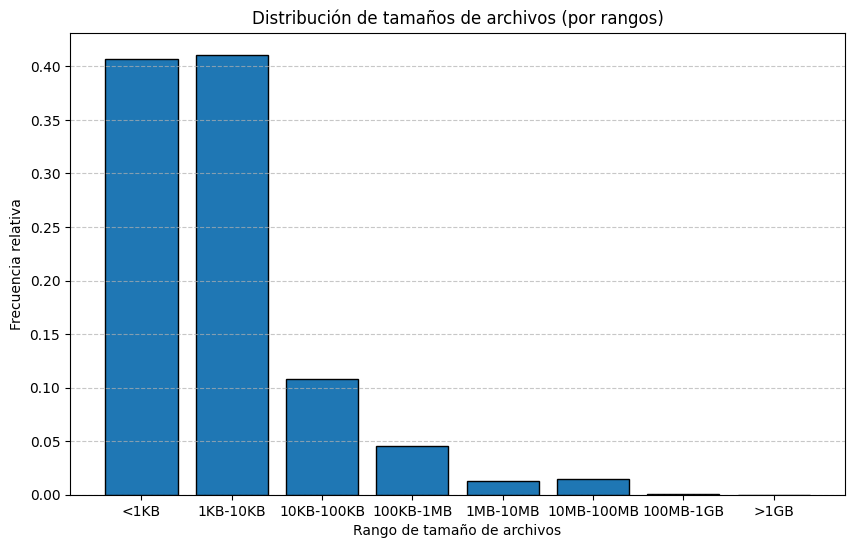

In [ ]:
# Crear bins hasta 1TB (~10**12) para incluir todo
bins = [0, 10**3, 10**4, 10**5, 10**6, 10**7, 10**8, 10**9, 10**12]
labels = ["<1KB","1KB-10KB","10KB-100KB","100KB-1MB",
          "1MB-10MB","10MB-100MB","100MB-1GB",">1GB"]
# Clasificar archivos en rangos
df_files['Rango'] = pd.cut(df_files['Tamaño (bytes)'], bins=bins, labels=labels, include_lowest=True)

# Agrupar por rango
df_grouped = df_files.groupby('Rango', observed=True)['Cantidad de archivos'].sum().reset_index()

# Calcular frecuencia relativa
total_archivos = df_grouped['Cantidad de archivos'].sum()
df_grouped['Frecuencia relativa'] = df_grouped['Cantidad de archivos'] / total_archivos

# Graficar
plt.figure(figsize=(10,6))
plt.bar(df_grouped['Rango'], df_grouped['Frecuencia relativa'], edgecolor="black")
plt.xlabel("Rango de tamaño de archivos")
plt.ylabel("Frecuencia relativa")
plt.title("Distribución de tamaños de archivos (por rangos)")
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.show()

En escala log-log:

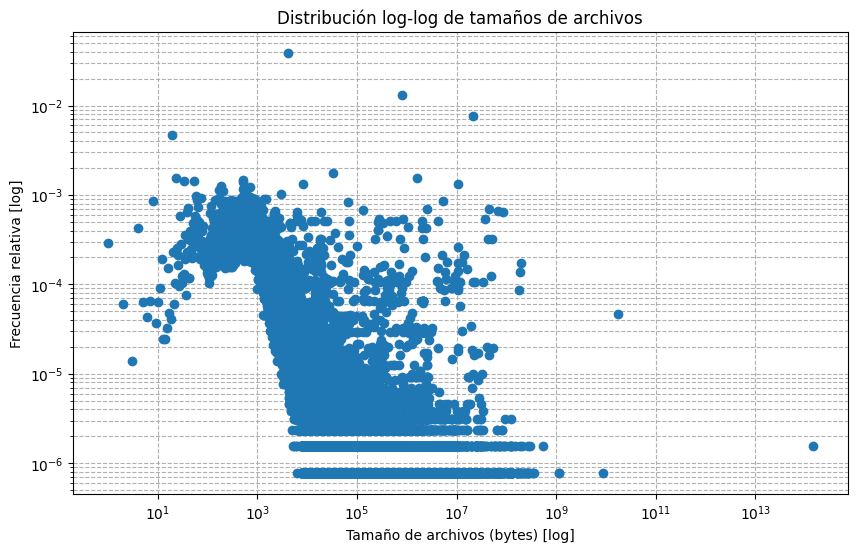

In [ ]:
plt.figure(figsize=(10, 6))
plt.loglog(df_files['Tamaño (bytes)'], df_files['Frecuencia relativa'], 'o')
plt.xlabel("Tamaño de archivos (bytes) [log]")
plt.ylabel("Frecuencia relativa [log]")
plt.title("Distribución log-log de tamaños de archivos")
plt.grid(True, which="both", ls="--")
plt.show()

La mayoría de los archivos pesa entre unas decenas de bytes y unos pocos kilobytes, pero la distribución se extiende por más de diez órdenes de magnitud, hasta archivos de gigabytes: una cola larga, típica de los sistemas de archivos. La nube no forma una recta limpia, así que tampoco aquí se puede afirmar una ley de potencia estricta.